# Demonstrating doves movie regen + STA convolution
VR March 5, 2026

Updated by VR Oct 22, 2026 with STA convolution part

In [24]:
import os

import matplotlib.pyplot as plt
from IPython.display import HTML

import retinanalysis as ra

In [2]:
ra.config.set_profile('nas')

Can fetch single cell data Sam pointed me to, or MEA data I'm used to.

In [25]:
exp_search = ra.get_datasets_from_protocol_names('dovesmovie')
available_experiments = os.listdir(ra.ANALYSIS_DIR)
exp_search = exp_search.query('exp_name in @available_experiments').reset_index(drop = True)
display(exp_search)


Found 1 protocols matching "dovesmovie":
['manookinlab.protocols.DovesMovie']

Found 51 experiments, 96 epoch blocks.



,exp_name,datafile_name,NDF,chunk_name,protocol_name,is_mea,data_dir,group_label,experiment_id,protocol_id,group_id,block_id,chunk_id
0,20230719C,data008,0.0,chunk1,manookinlab.protocols.DovesMovie,1,20230719C/data008,doves repeats,4,6,81,93,10
1,20230719C,data028,0.0,chunk3,manookinlab.protocols.DovesMovie,1,20230719C/data028,doves repeats,4,6,95,112,12
2,20250128C,data002,1.0,doves,manookinlab.protocols.DovesMovie,1,20250128C/data002,Doves 4k,7,6,116,174,24
3,20250128C,data003,0.5,doves,manookinlab.protocols.DovesMovie,1,20250128C/data003,Doves 13k,7,6,117,175,24
4,20250128C,data004,0.0,doves,manookinlab.protocols.DovesMovie,1,20250128C/data004,Doves 40k,7,6,118,176,24
...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,20260415C,data034,1.0,nat_images,manookinlab.protocols.DovesMovie,1,20260415C/data034,natural,204,6,3079,4959,922
91,20260602C,data015,1.0,nat_images,manookinlab.protocols.DovesMovie,1,20260602C/data015,doves,210,6,3145,5058,961
92,20260602C,data016,1.0,nat_images,manookinlab.protocols.DovesMovie,1,20260602C/data016,doves,210,6,3145,5059,961
93,20260625C,data017,1.0,natural_images,manookinlab.protocols.DovesMovie,1,20260625C/data017,doves with FEM,214,6,3181,5149,972


In [39]:
# exp_name = '2026-02-24_E_2'
exp_name = '20260415C'
df_exp = ra.get_exp_summary(exp_name)
# df_exp.query('cell_label=="Cell6" & protocol_name=="manookinlab.protocols.DovesMovie"')
df_exp.query('protocol_name=="manookinlab.protocols.DovesMovie"')

,exp_name,prep_label,datafile_name,group_label,NDF,chunk_name,protocol_name,duration_minutes,minutes_since_start,start_time,end_time,data_dir,experiment_id,prep_id,group_id,block_id,chunk_id,protocol_id
32,20260415C,Mount1,data034,natural,1.0,nat_images,manookinlab.protocols.DovesMovie,5.82,509.1,2026-04-15 23:17:21,2026-04-15 23:23:10,20260415C/data034,204,241,3079,4959,922,6


Load stim block

In [40]:
pl = ra.create_mea_pipeline(exp_name, 'data034')#, 'chunk3')
# sb = ra.MEAStimBlock(exp_name, 'data006')
# sb
sb = pl.stim

Initializing StimBlock for 20260415C block 4959

For experiment 20260415C and block 4959:
    -disp_type: LCR
    -mode: video
    -mu_per_pixel: 3.07
    -n_ht: 1140.0
    -n_wt: 1824.0
    -mean_frame_rate: 59.951813050743944
    -stage_frame_rate: 59.0
    -upsample_rate: 1

Nearest noise chunk for data034 is chunk3 with distance 74 minutes.

Initializing ResponseBlock for 20260415C block 4959
Loading VCD from /mnt/Volumes/data-1/data/sorted/20260415C/data034/kilosort2.5 ...
VCD loaded with 435 cells.

Using chunk3 for AnalysisChunk

Loading VCD from /mnt/Volumes/data-1/analysis/20260415C/chunk3/kilosort2.5 ...
VCD loaded with 419 cells.


Loaded spatial maps for channels [0, 2] and 419 cells of shape (114, 183, 2)
Spatial maps have been padded to align with RF parameters.

Cluster matching 20260415C chunk3 with DovesMovie ...
82.82% matched, 17.18% unmatched.

Using vr_kilosort2.5.classification.txt for classification.



In [41]:
pl.analysis_chunk.df_cell_params

,cell_id,center_x,center_y,std_x,std_y,rot,typing_file_0,typing_file_1
0,1,107.182426,53.335693,3.166641,2.777765,106.628853,OffM,OffM
1,2,106.867096,51.368137,7.410503,5.190970,122.946899,Unknown,SBC
2,3,106.523590,58.233276,2.045437,2.934586,80.991631,OffS,OffS
3,5,106.780525,62.124687,4.693294,3.914499,84.251602,OnP,OnM
4,6,104.704582,65.757042,2.902298,3.344814,131.854050,OnM,OnM
...,...,...,...,...,...,...,...,...
414,482,109.423538,67.775551,2.656359,3.127382,111.354088,OnM,OnM
415,484,75.295654,44.736141,2.490872,3.001666,178.161270,Unknown,OffS
416,486,106.007270,56.211682,31.060836,18.586441,15.205072,Unknown,Unknown
417,488,85.051868,48.277388,10.783877,5.845579,105.699585,Unknown,Amacrine


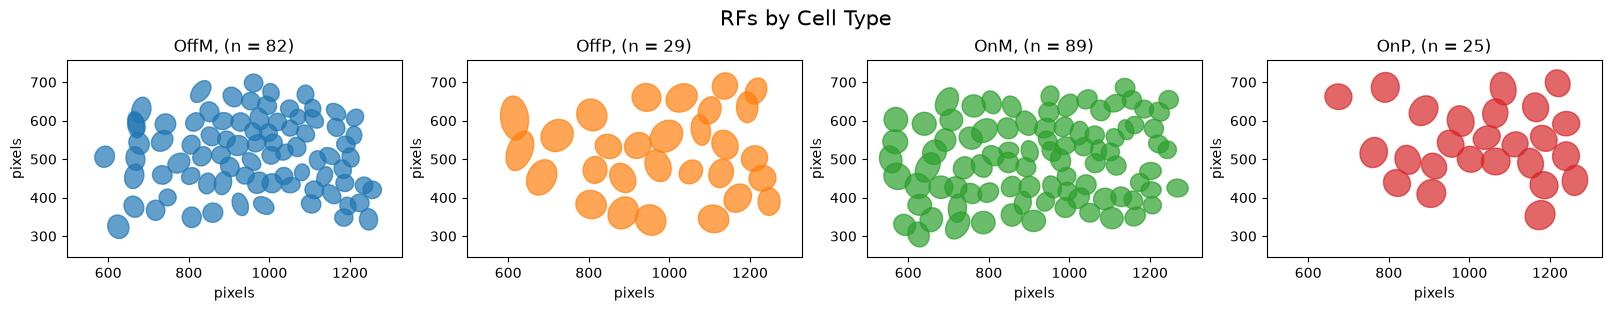

In [42]:
_ = pl.plot_rfs(cell_types=['OffP', 'OffM', 'OnP', 'OnM'], b_zoom=True)

In [44]:
# Set spatial dimensions to downsample doves movies to be noise stixel space
stix_dims = (pl.analysis_chunk.numYChecks, pl.analysis_chunk.numXChecks)
print(stix_dims)

(114, 183)


In [45]:
sb.regenerate_stimulus(
    # Only doing first epoch, you can leave out this arg for regenerating all epochs
    ls_epochs = [0], 
    str_manookin_pkg_dir='/home/vyomr/Desktop/gitrepos/manookin-package',
    verbose=True,
    # Downsample params, arbitrary in SC but in MEA I typically go to noise stixel space
    b_ds_to_stix=True,
    stix_dims=stix_dims
)

Regenerating stimulus for epochs: [0] in block: 4959
Using regeneration function: make_all_doves_movies
Processing epoch 1/1
Movie params: 
    magnificationFactor: 4.0
    stimulusIndex: 2 (matlab 1-based index)
    waitTime: 1.00 s
    stimTime: 6.00 s
    wait_frames: 59
    total_frames: 354
Loading image imk00031.iml from /home/vyomr/Desktop/gitrepos/manookin-package/resources/doves/images/imk00031.iml
Creating movie for imk00031.iml with shape (4096, 6144) and scene size [4096 6144], fitting in [1140 1824]
And downsampling to stix dims (114, 183).


Generating frames: 100%|██████████| 295/295 [00:09<00:00, 32.77it/s]

Adding 59 wait frames to (295, 114, 183) for 1.0 s.
New frames shape: (354, 114, 183)
Movie scaled to (-1, 1) contrast: min -0.90, max 0.29
All movies have same frame count of 354, stacking into array.
Regenerated stimulus with keys: ['movies', 'image_names', 'images', 'center_x_pos', 'center_y_pos']


Animating the movie

In [7]:
def animate_vid(vid, interval=100, rescale=True):
    from matplotlib import animation
    import matplotlib.pyplot as plt
    if rescale:
        vid = (vid+1)/2
    fig, ax = plt.subplots()
    # ax.axis('off')
    im = ax.imshow(vid[0, ...], cmap='gray', vmin=0, vmax=1)
    plt.close()

    def init():
        im.set_array(vid[0, ...])
        return im

    def animate(i):
        im.set_array(vid[i, ...])
        return im

    ani = animation.FuncAnimation(fig, animate, frames=vid.shape[0], init_func=init, interval=interval)
    return ani

In [2]:
# Scale from (-1,1) to (0,1) for plotting
# Run this if you want to see the animation in your jupyter notebook. Commenting out as it breaks the preview on github
# movie = sb.stim_data['movies'][0]
# ani_input = (movie + 1)/2
# ani = animate_vid(ani_input,1/(60.3*2)*1e3, False)
# HTML(ani.to_jshtml())

The full image, and the display in pixels that crops the image

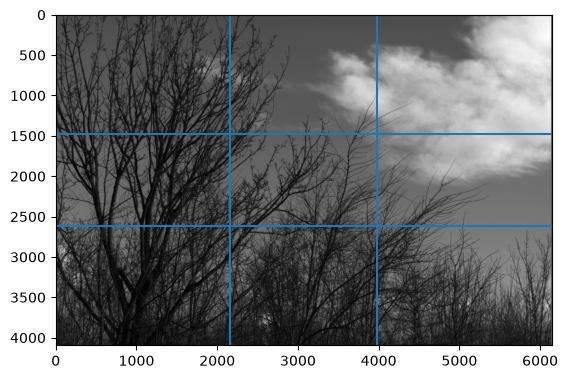

In [46]:
img = sb.stim_data['images'][0]
plt.imshow(img, cmap='gray')
cr, cc = img.shape[0]/2, img.shape[1]/2
ht, wt = sb.d_display['n_ht'], sb.d_display['n_wt']
plt.axvline(cc-wt/2)
plt.axvline(cc+wt/2)
plt.axhline(cr-ht/2)
plt.axhline(cr+ht/2)

The eye movement trajectory in pixel space

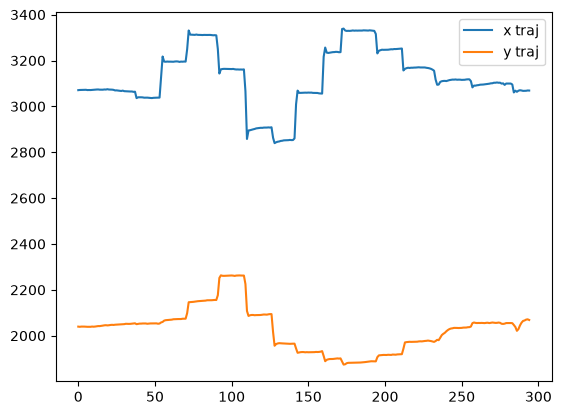

In [47]:
plt.plot(sb.stim_data['center_x_pos'][0], label='x traj')
plt.plot(sb.stim_data['center_y_pos'][0], label='y traj')
plt.legend()

## STA convolved with stimulus

Let's get 2 example Off Parasol cells, compute Linear Filter output, and compare to spikerate for epoch 0

In [57]:
import numpy as np
import torch

In [48]:
pl.resp.df_spike_times['cell_type'].value_counts()

cell_type
OnM          89
Unmatched    88
OffM         82
Unknown      62
OffS         30
OffP         29
OnP          25
OnS          22
Amacrine      8
Name: count, dtype: int64

In [49]:
pl.resp.bin_spike_times_by_frames(stride=1)

  0%|          | 0/435 [00:00<?, ?it/s]

/home/vyomr/Desktop/gitrepos/retinanalysis/src/retinanalysis/classes/response.py:1164: UserWarning: Not all epochs have same number of frames. Returning list of lists.
  binned_spikes = _bin_spike_times_by_frames(


In [83]:
str_type = 'OffP'
n_cells = 2

df_st = pl.resp.df_spike_times
df_type = df_st[df_st['cell_type']==str_type]

type_noise_ids = df_type['noise_id'].values
sel_noise_ids = type_noise_ids[:n_cells]
sel_protocol_ids = df_type['cell_id'].values[:n_cells]
sel_cell_idx = df_type.index.values[:n_cells]
print(f'Selected cell IDs {sel_noise_ids} of type {str_type}')

Selected cell IDs [11 27] of type OffP


In [51]:
# Returns {type: {id: sta}}
d_stas = pl.analysis_chunk.get_stas(noise_ids=sel_noise_ids, padded=True)

In [58]:
# Organize STAs into stacked arrays of shape [K cells, D depth, H ht, W wt, C channels]
def organize_stas(d_stas: dict[str: dict[int: np.ndarray]], t_ds: int=1):
    ls = []
    for d in d_stas.values():
        for sta in d.values():
            ls.append(sta[::t_ds])

    stas = np.stack(ls)
    print(f'Stacked STAs in {stas.shape}')
    return stas

# Downsample STAs temporally by 2, assuming they were computed at 120Hz and now I want to convolve with 60Hz stim
stas = organize_stas(d_stas, t_ds=2)

Stacked STAs in (2, 31, 114, 183, 3)


Filter class in pytorch

In [74]:
class SpatiotemporalFilters(torch.nn.Module):
    def __init__(
        self, preset_filters: torch.Tensor,
        n_stride: int=1, device: str='cpu',             
    ):
        # centered_filter is of shape [depth, ht, wt, channels]
        # spatial_dims is of shape [ht, wt]
        super().__init__()
        self.device = device
        # Convolution stride
        self.n_stride = int(n_stride) 

        self.n_filters = preset_filters.shape[0]
        self.n_depth = preset_filters.shape[1]
        self.n_channels = preset_filters.shape[4]
        
        if isinstance(preset_filters, np.ndarray):
            preset_filters = torch.from_numpy(preset_filters)

        filters = preset_filters.to(self.device).to(torch.float32)
        self.flat_filter = torch.reshape(filters, (self.n_filters, self.n_depth, -1))
    
    def forward(self, x: torch.Tensor):
        # Input of shape [n_frames, n_ht, n_wt, n_channels]
        # Output of shape [n_filters, n_frames]
        if isinstance(x, np.ndarray):
            x = torch.from_numpy(x)
        
        n_frames = x.shape[0]
        n_depth = self.n_depth

        flat_x = torch.reshape(x, (n_frames, -1)).to(self.device).to(torch.float32)
        output = torch.zeros((self.n_filters,n_frames)).to(self.device).to(torch.float32)

        if n_frames < n_depth*self.n_stride:
            n_depth = n_frames//self.n_stride
        
        for offset in range(n_depth):
            output[:, (offset * self.n_stride):] +=\
                torch.matmul(self.flat_filter[:, offset, :],
                            flat_x[:n_frames - (offset * self.n_stride), :].T)
        
        self.gs = output.clone().detach().cpu()
        self.output = output
        return self.output

In [75]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
f = SpatiotemporalFilters(stas, 1, device)

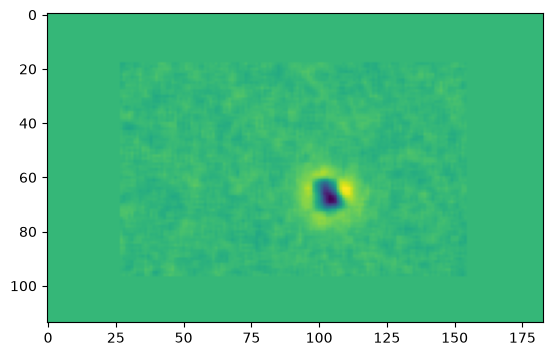

In [76]:
# Example frame
plt.imshow(stas[0,-2,:,:,0])

In [91]:
# First epoch, which is all we regenerated
epoch_idx = 0
x = sb.stim_data['movies'][epoch_idx]

# Repeat for 3 channel input
x = np.repeat(x[:,:,:,np.newaxis], 3, axis=3)
print(x.shape)

(354, 114, 183, 3)


In [78]:
y = f(x).detach().cpu().numpy()
y.shape

(2, 354)

Comparison with true binned spikecount

In [123]:
# [K cells, T timepoints]
true = np.array([pl.resp.binned_spikes[ci][epoch_idx] for ci in sel_cell_idx], dtype=np.float32)

pre_time_s = sb.d_epoch_block_params['preTime'] / 1e3
pre_frames = round(pre_time_s*sb.d_display['stage_frame_rate'])
movie_frames = x.shape[0]
true = true[:, pre_frames:pre_frames+movie_frames]
print(true.shape)

(2, 354)


Text(0.5, 1.0, 'OffP noise ID 27\nr=0.19')

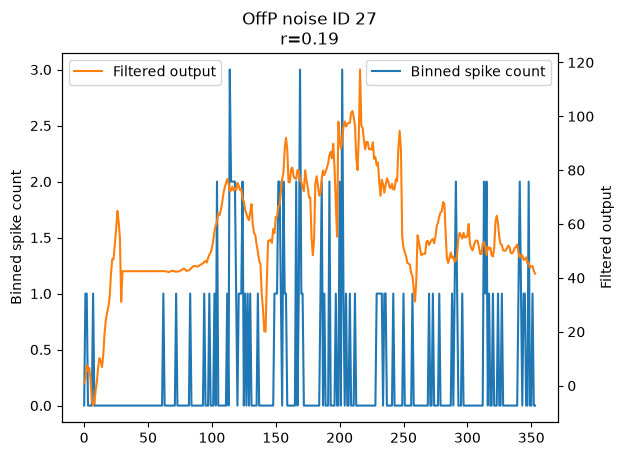

In [122]:
i_cell = 1
plt.plot(true[i_cell], c='C0', label='Binned spike count')
plt.ylabel('Binned spike count')
plt.legend(loc='upper right')
plt.twinx()
plt.plot(y[i_cell], c='C1', label='Filtered output')
plt.ylabel('Filtered output')
plt.legend(loc='upper left')
r = np.corrcoef(true[i_cell], y[i_cell])[0,1]
plt.title(f'{str_type} noise ID {sel_noise_ids[i_cell]}\nr={r:.2f}')

That looks decent to me, probably would be improved with smoothing the spikerate and nonlinearity at the end for a proper LN model!